In [ ]:
import marimo as mo

# Exploración para redefinir la pregunta del proyecto

Los EDA de cada dataset (notebooks 05 a 07 y la carpeta `AAMM/`) cumplieron las secciones
del curso, pero sin una pregunta común no dejaron un hallazgo que encabece el reporte.
Este notebook cruza las fuentes en el tiempo para decidir qué pregunta sostienen los datos.

Pregunta candidata: ¿cuándo y en qué colonias de Hermosillo se concentran las afectaciones
urbanas ligadas al agua, y cuánto de ese patrón explican la lluvia y la cercanía a los
cauces?

Fuentes:

- Llamadas al 911 de 2018 a 2025, filtradas a 32 tipos de incidente ligados al agua y al
  terreno (`llamadas_911_hermosillo.csv`).
- Precipitación diaria de Open-Meteo, estimación de reanálisis (`precipitacion_hermosillo.csv`),
  fuente nueva de esta exploración.
- Reportes del Bachómetro de 2021 a 2026 (`baches_hermosillo.csv`).
- Publicaciones de Agua de Hermosillo en Facebook (`publicaciones_aguah.csv`).
- Colonias del DCAH 2025 y red hidrográfica 1:50k del INEGI.

## Exploraciones

| Id | Pregunta | Se conserva si |
|---|---|---|
| E8 | ¿Qué cobertura real tiene cada fuente? | Siempre: define la ventana y las limitaciones |
| E1 | ¿Las fuentes comparten calendario? | El pico de julio a septiembre aparece cada año |
| E2 | ¿Es la lluvia? | La respuesta tras lluvia supera a los días secos del mismo mes |
| E3 | ¿Hay una temporada de agua que falta? | El pico seco aparece en al menos 3 de 5 años |
| E4 | ¿Son siempre las mismas colonias? | Persistencia entre años mayor a 0.5, o diferencia por cauce con control |
| E5 | ¿Qué días son anómalos? | Los días marcados coinciden con lluvia o episodios conocidos |
| E6 | ¿Hay perfiles de colonia? | PC1 separa colonias de perfil lluvioso |
| E7 | ¿El texto confirma la causa? | La mención de lluvia sube en los mismos meses |

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

from project_name import water_events as we
from project_name.eda import (
    CATEGORICAL,
    NEUTRAL,
    agreement_table,
    embed_2d,
    embedding_quality,
    iqr_outliers,
    pyod_outliers,
)

pd.set_option("display.max_rows", 60)

In [ ]:
rain = we.load_rain()
colonias = we.load_colonias()
calls = we.load_calls(colonias)
baches = we.load_baches()
posts = we.load_posts()

## E8. Cobertura y datos faltantes

Antes de comparar series hay que saber qué meses cubre cada fuente y qué parte de cada
una se puede ubicar en una colonia.

In [ ]:
def _span(dates: pd.Series) -> tuple[str, str]:
    return dates.min().strftime("%Y-%m-%d"), dates.max().strftime("%Y-%m-%d")

coverage_table = pd.DataFrame(
    [
        ("lluvia", len(rain), *_span(rain.index.to_series())),
        ("911", len(calls), *_span(calls["date"])),
        ("baches", len(baches), *_span(baches["date"])),
        ("aguah", len(posts), *_span(posts["date"])),
    ],
    columns=["fuente", "filas", "desde", "hasta"],
)
coverage_table

,fuente,filas,desde,hasta
0,lluvia,3195,2018-01-01,2026-09-30
1,911,4176,2018-01-05,2025-09-30
2,baches,39018,2021-09-17,2026-09-28
3,aguah,5200,2020-12-07,2026-09-14


In [ ]:
_months = pd.period_range("2018-01", "2026-09", freq="M")
monthly_rows = pd.DataFrame(
    {
        "911": calls.groupby(calls["date"].dt.to_period("M")).size(),
        "baches": baches.groupby(baches["date"].dt.to_period("M")).size(),
        "aguah": posts.groupby(posts["date"].dt.to_period("M")).size(),
    }
).reindex(_months)
# Meses sin un solo registro dentro del periodo de cada fuente: huecos de captura.
gaps = {
    source: [
        str(month)
        for month in monthly_rows.index[monthly_rows[source].isna()]
        if monthly_rows[source].first_valid_index()
        < month
        < monthly_rows[source].last_valid_index()
    ]
    for source in monthly_rows.columns
}
gaps

In [ ]:
_in_city = baches["latitude"].between(28.8, 29.3) & baches["longitude"].between(-111.2, -110.8)
quality_table = pd.DataFrame(
    {
        "valor": [
            round(100 * calls["colonia_id"].notna().mean(), 1),
            int((calls["colonia"] == "SIN COLONIA").sum()),
            int((~_in_city).sum()),
            int((baches["year"] != baches["date"].dt.year).sum()),
            int(baches.duplicated(["latitude", "longitude", "date", "description"]).sum()),
        ]
    },
    index=[
        "% de llamadas 911 con colonia única por nombre",
        "llamadas 911 con colonia 'SIN COLONIA'",
        "baches fuera del recuadro de la ciudad",
        "baches con year distinto al año de date",
        "baches repetidos (coordenada, fecha y texto)",
    ],
)
quality_table

,valor
% de llamadas 911 con colonia única por nombre,67.0
llamadas 911 con colonia 'SIN COLONIA',57.0
baches fuera del recuadro de la ciudad,511.0
baches con year distinto al año de date,1584.0
"baches repetidos (coordenada, fecha y texto)",152.0


In [ ]:
calls_by_year = pd.crosstab(calls["date"].dt.year, calls["grupo_incidente"])
calls_by_year

grupo_incidente,ahogamiento_acuaticos,drenaje_y_red_de_agua,fenomeno_hidrometeorologico,inundacion_directa,terreno
date,,,,,
2018,11,108,0,153,232
2019,10,110,0,63,242
2020,7,53,0,3,168
2021,19,154,0,71,327
2022,15,205,0,90,515
2023,10,157,0,7,271
2024,5,135,0,17,381
2025,7,144,27,50,409


Lectura:

- La ventana común a lluvia, 911 y baches es de enero de 2022 a septiembre de 2025. El 911
  solo tiene sentido hasta septiembre de 2025, y los baches de 2021 empiezan en septiembre.
- Agua de Hermosillo tiene un hueco del 5 al 19 de abril de 2024 (visto en el notebook 05)
  y agosto y septiembre de 2026 incompletos, por eso su serie se corta en julio de 2026.
- Una de cada tres llamadas al 911 no se puede ubicar en una colonia de la ciudad por
  nombre. Los análisis por colonia trabajan con el 67% restante; los análisis temporales
  usan todas las llamadas.
- `fenomeno_hidrometeorologico` solo existe en 2025: es un cambio de catálogo, no un
  fenómeno nuevo, así que no se compara entre años.
- Los baches usan `date`, no `year`, porque `year` es el archivo de origen y no coincide en
  1,584 filas.

## E1. ¿Las fuentes comparten calendario?

Participación de cada mes en el total de su año, solo años completos. Si una serie no
tiene estacionalidad, cada mes ronda 8.3% y julio a septiembre suman 25%.

In [ ]:
_calls_years = list(range(2018, 2025))
_rain_frame = rain.to_frame("mm").reset_index()
_rain_frame = _rain_frame[_rain_frame["date"].dt.year.between(2018, 2025)]
_rain_share = (
    _rain_frame.groupby([_rain_frame["date"].dt.year, _rain_frame["date"].dt.month])["mm"]
    .sum()
    .unstack()
)
_rain_share = _rain_share.div(_rain_share.sum(axis=1), axis=0).mul(100)
shares = {
    "lluvia (mm)": _rain_share,
    "911 inundación": we.monthly_share(
        calls[calls["grupo_incidente"] == "inundacion_directa"], _calls_years
    ),
    "911 terreno": we.monthly_share(
        calls[calls["grupo_incidente"] == "terreno"], _calls_years
    ),
    "911 drenaje": we.monthly_share(
        calls[calls["grupo_incidente"] == "drenaje_y_red_de_agua"], _calls_years
    ),
    "baches": we.monthly_share(baches, [2022, 2023, 2024, 2025]),
    "aguah emergencia": we.monthly_share(
        posts[posts["event_type"] == "emergencia"], [2021, 2022, 2023, 2024, 2025]
    ),
}
jas_share = pd.DataFrame(
    {name: frame[[7, 8, 9]].sum(axis=1).round(1) for name, frame in shares.items()}
)
jas_share

,lluvia (mm),911 inundación,911 terreno,911 drenaje,baches,aguah emergencia
date,,,,,,
2018,59.9,92.2,67.2,41.7,NaN,NaN
2019,44.3,77.8,71.0,32.8,NaN,NaN
2020,36.4,33.3,67.2,24.5,NaN,NaN
2021,78.3,88.7,74.3,47.4,NaN,25.0
2022,91.8,92.3,63.5,28.7,24.8,45.1
2023,34.3,71.5,57.2,25.5,25.6,26.4
2024,43.3,29.4,62.8,25.2,27.3,24.3
2025,70.2,NaN,NaN,NaN,24.4,25.5


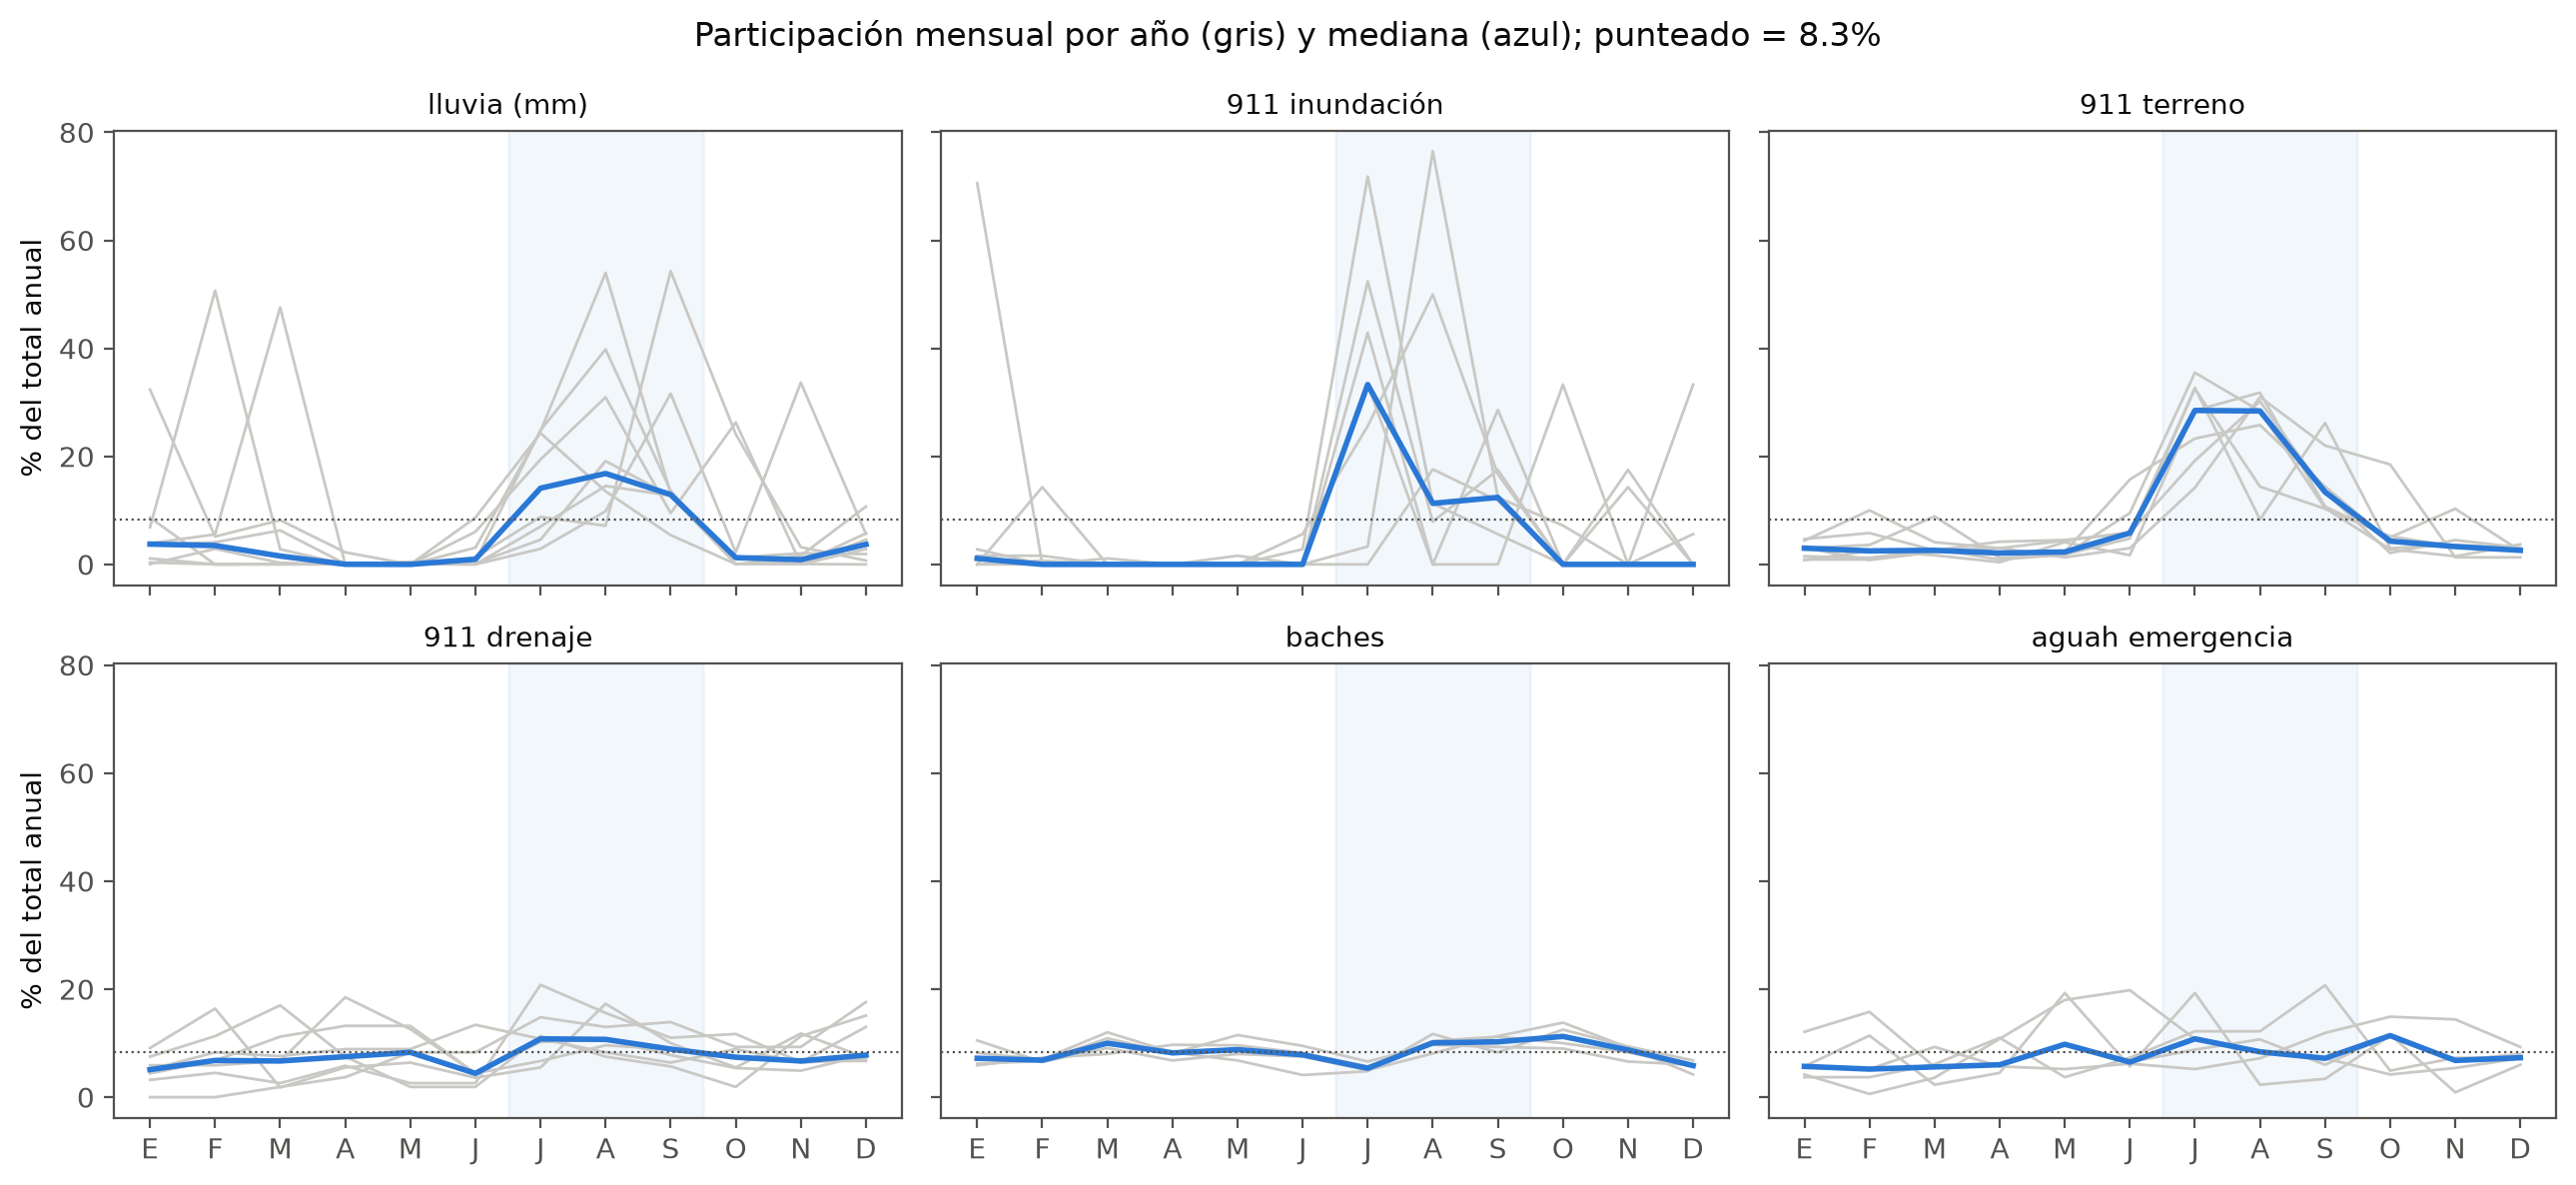

In [ ]:
_fig, _axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for _ax, (_name, _frame) in zip(_axes.flat, shares.items()):
    for _year, _row in _frame.iterrows():
        _ax.plot(range(1, 13), _row.reindex(range(1, 13)).values, color="#c9c8c4", lw=1)
    _ax.plot(
        range(1, 13),
        _frame.reindex(columns=range(1, 13)).median().values,
        color=CATEGORICAL[0],
        lw=2,
    )
    _ax.axhline(100 / 12, color="#52514e", lw=0.8, ls=":")
    _ax.axvspan(6.5, 9.5, color=CATEGORICAL[0], alpha=0.06)
    _ax.set_title(_name, fontsize=10)
    _ax.set_xticks(np.arange(1, 13), list("EFMAMJJASOND"))
_axes[0, 0].set_ylabel("% del total anual")
_axes[1, 0].set_ylabel("% del total anual")
_fig.suptitle("Participación mensual por año (gris) y mediana (azul); punteado = 8.3%")
_fig.tight_layout()
_fig

In [ ]:
_rows = jas_share.round(0).astype("Int64").to_string()
mo.md(f"""
Lectura:

- Las llamadas por terreno (árbol caído, hundimiento, derrumbe, socavón) concentran entre
  57% y 74% del año en julio a septiembre, los 7 años completos.
- Las de inundación concentran entre 71% y 92% en 2018, 2019, 2021, 2022 y 2023. En 2020 y
  2024 el porcentaje no dice nada: hubo 3 y 17 llamadas en todo el año, los años más
  secos junto con 2023.
- Los baches no se concentran en la temporada de lluvias: julio a septiembre suman entre
  24% y 27%, lo mismo que una serie plana. El salto de julio a agosto que se veía en
  `docs/cinco_v_datos.md` viene de que julio es el mes más bajo, no de un pico en agosto.
- Las emergencias de Agua de Hermosillo rondan 25% salvo en 2022 (45%).
- Resultado: E1 se sostiene para el 911 y se descarta para baches y Agua de Hermosillo.

```
{_rows}
```
""")

Lectura:

- Las llamadas por terreno (árbol caído, hundimiento, derrumbe, socavón) concentran entre
  57% y 74% del año en julio a septiembre, los 7 años completos.
- Las de inundación concentran entre 71% y 92% en 2018, 2019, 2021, 2022 y 2023. En 2020 y
  2024 el porcentaje no dice nada: hubo 3 y 17 llamadas en todo el año, los años más
  secos junto con 2023.
- Los baches no se concentran en la temporada de lluvias: julio a septiembre suman entre
  24% y 27%, lo mismo que una serie plana. El salto de julio a agosto que se veía en
  `docs/cinco_v_datos.md` viene de que julio es el mes más bajo, no de un pico en agosto.
- Las emergencias de Agua de Hermosillo rondan 25% salvo en 2022 (45%).
- Resultado: E1 se sostiene para el 911 y se descarta para baches y Agua de Hermosillo.

```
      lluvia (mm)  911 inundación  911 terreno  911 drenaje  baches  aguah emergencia
date                                                                                 
2018           60              92           67           42    <NA>              <NA>
2019           44              78           71           33    <NA>              <NA>
2020           36              33           67           24    <NA>              <NA>
2021           78              89           74           47    <NA>                25
2022           92              92           64           29      25                45
2023           34              72           57           26      26                26
2024           43              29           63           25      27                24
2025           70            <NA>         <NA>         <NA>      24                26
```

## E2. ¿Es la lluvia?

La estacionalidad sola no prueba que la causa sea la lluvia: en verano también hay calor,
vacaciones y más gente en la calle. Dos pruebas que separan la lluvia de la temporada:

1. Correlación de Spearman entre la lluvia del día t y el conteo del día t + k.
2. Estudio de evento dentro de los meses de junio a octubre: conteo diario medio en los 8
   días que siguen a una lluvia de 10 mm o más, contra los días sin lluvia en los 8 días
   previos. Al comparar dentro de la misma temporada, el calor y las vacaciones se
   cancelan.

In [ ]:
daily_series = {
    "911 inundación": we.daily_counts(
        calls[calls["grupo_incidente"] == "inundacion_directa"], "911"
    ),
    "911 terreno": we.daily_counts(calls[calls["grupo_incidente"] == "terreno"], "911"),
    "911 drenaje": we.daily_counts(
        calls[calls["grupo_incidente"] == "drenaje_y_red_de_agua"], "911"
    ),
    "baches": we.daily_counts(baches, "baches"),
    "aguah emergencia": we.daily_counts(posts[posts["event_type"] == "emergencia"], "aguah"),
}
daily = we.daily_table(rain, daily_series)

In [ ]:
lag_table = pd.DataFrame(
    [we.lagged_spearman(daily, _name, [0, 1, 2, 3, 7, 14, 30]) for _name in daily_series]
).round(3)
lag_table.columns.name = "rezago (días)"
lag_table

rezago (días),0,1,2,3,7,14,30
911 inundación,0.299,0.239,0.231,0.181,0.143,0.113,0.057
911 terreno,0.312,0.260,0.247,0.234,0.194,0.178,0.123
911 drenaje,0.108,0.119,0.098,0.082,0.067,0.065,0.035
baches,-0.004,-0.017,0.032,0.025,0.035,0.021,0.068
aguah emergencia,0.008,0.058,0.039,0.059,-0.002,-0.015,-0.015


In [ ]:
event_table = pd.DataFrame([we.event_study(daily, _name) for _name in daily_series])
event_table

,serie,días tras lluvia,media tras lluvia,días secos,media en secos,razón
0,911 inundación,167,1.41,586,0.06,21.70
1,911 terreno,167,3.14,586,0.86,3.66
2,911 drenaje,167,0.74,586,0.30,2.47
3,baches,118,28.70,343,20.15,1.42
4,aguah emergencia,122,0.47,409,0.47,0.99


In [ ]:
# Control más estricto: húmedo contra seco dentro de cada mes de cada año, para que
# la tendencia de largo plazo (más baches cada año) no entre en la comparación. Se
# cuentan meses en lugar de promediar razones porque muchos meses secos tienen 0
# llamadas por inundación y la razón sería infinita.
def _summary(_m: pd.DataFrame) -> dict:
    return {
        "meses comparables": len(_m),
        "húmedo > seco": int((_m["húmedo"] > _m["seco"]).sum()),
        "húmedo < seco": int((_m["húmedo"] < _m["seco"]).sum()),
        "media húmedo / media seco": round(_m["húmedo"].mean() / _m["seco"].mean(), 2),
    }

within_month = pd.DataFrame(
    {
        _name: _summary(we.within_month_ratio(daily, _name))
        for _name in ["911 inundación", "911 terreno", "911 drenaje", "baches"]
    }
).T
within_month

,meses comparables,húmedo > seco,húmedo < seco,media húmedo / media seco
911 inundación,26.0,14.0,2.0,31.24
911 terreno,26.0,17.0,9.0,1.52
911 drenaje,26.0,17.0,9.0,1.52
baches,12.0,5.0,7.0,0.97


In [ ]:
_annual_rain = (
    rain[rain.index.year <= 2025].groupby(rain.index.year[rain.index.year <= 2025]).sum()
)
annual = pd.DataFrame(
    {
        "lluvia mm": _annual_rain.round(0),
        "911 inundación": calls[calls["grupo_incidente"] == "inundacion_directa"]
        .groupby(calls["date"].dt.year)
        .size(),
        "911 terreno": calls[calls["grupo_incidente"] == "terreno"]
        .groupby(calls["date"].dt.year)
        .size(),
    }
).dropna()
annual_spearman = annual.corr(method="spearman")["lluvia mm"].round(2)
annual, annual_spearman

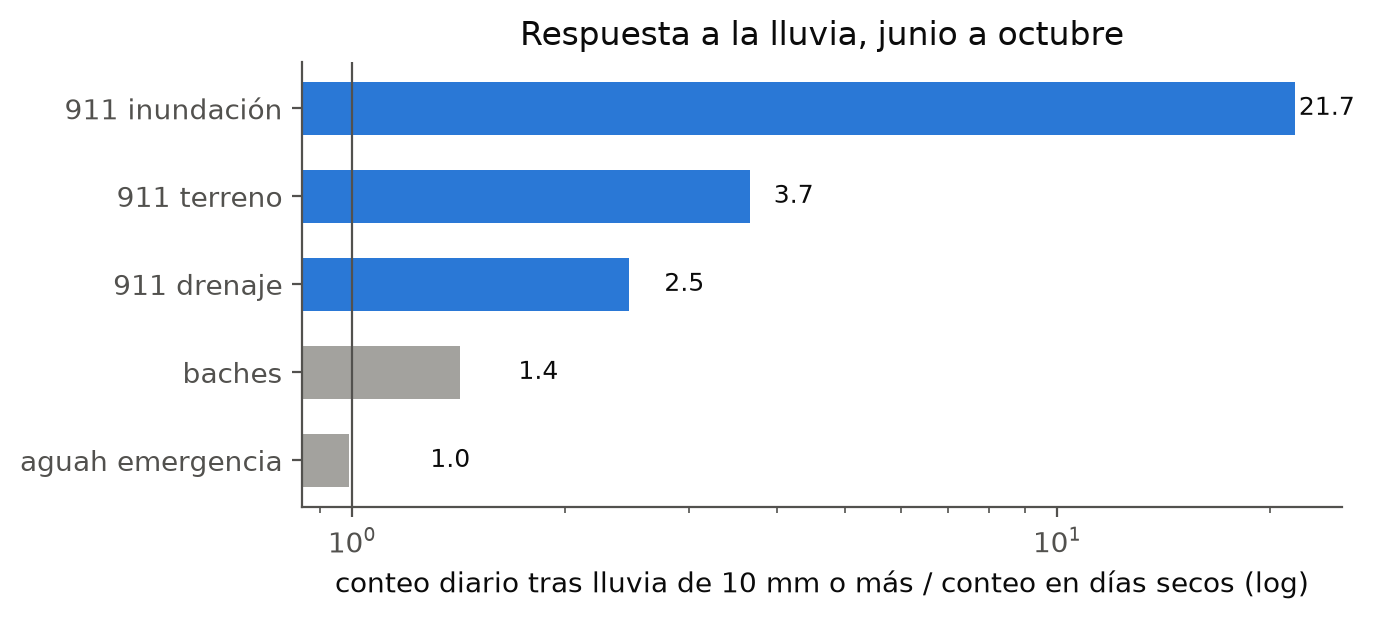

In [ ]:
_fig, _ax = plt.subplots(figsize=(7, 3.2))
_ordered = event_table.sort_values("razón")
_colors = [CATEGORICAL[0] if s.startswith("911") else NEUTRAL for s in _ordered["serie"]]
_ax.barh(_ordered["serie"], _ordered["razón"], color=_colors, height=0.6)
_ax.axvline(1, color="#52514e", lw=0.8)
for _y, _value in enumerate(_ordered["razón"]):
    _ax.text(_value + 0.3, _y, f"{_value:.1f}", va="center", fontsize=9)
_ax.set_xscale("log")
_ax.set_xlabel("conteo diario tras lluvia de 10 mm o más / conteo en días secos (log)")
_ax.set_title("Respuesta a la lluvia, junio a octubre")
_ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

Lectura:

- Las llamadas por inundación se multiplican por 21.7 en los días que siguen a una lluvia
  de 10 mm o más, comparadas con días secos de la misma temporada. Terreno se multiplica
  por 3.7 y drenaje por 2.5.
- El efecto sobrevive al control dentro del mismo mes: en inundación, de 26 meses
  comparables, 14 tienen más llamadas en días húmedos y solo 2 menos (los demás empatan
  en cero). Terreno y drenaje quedan arriba en 17 de 26 meses, con razón de 1.5.
- La respuesta es inmediata: la correlación más alta es el mismo día (rezago 0, Spearman
  0.30 en inundación y 0.31 en terreno) y decae en una semana.
- A escala anual también se ve: 2020, 2023 y 2024, los años más secos (162, 78 y 148 mm),
  tienen las cifras más bajas de llamadas por inundación (3, 7 y 17).
- Los baches no responden a la lluvia. La razón global de 1.4 desaparece dentro del mismo
  mes (0.97, más baches en días húmedos en 5 de 12 meses): era el efecto de que hay más
  baches cada año y los años recientes tuvieron más lluvia.
- Las emergencias de Agua de Hermosillo tampoco responden (razón 0.99).
- Punto de decisión: E1 y E2 se sostienen para el 911. La pregunta candidata se adopta,
  con las llamadas al 911 como serie principal; los baches salen de la pregunta.

## E3. ¿Hay una temporada de agua que falta?

Si la escasez fuera estacional, las emergencias, los cortes y las pipas se concentrarían
en abril a junio, antes del monzón. Se mide la participación de ese trimestre cada año
(25% sería una serie plana) y la participación de cada tipo de evento en las publicaciones
de cada mes.

In [ ]:
_complete = posts[posts["date"].dt.year.between(2021, 2025)]
_emergencies = _complete[_complete["event_type"] == "emergencia"]
dry_season = pd.DataFrame(
    {
        "emergencias": _emergencies.groupby(_emergencies["date"].dt.year).size(),
        "% en abril a junio": _emergencies.groupby(_emergencies["date"].dt.year)["date"]
        .apply(lambda _d: 100 * _d.dt.month.isin([4, 5, 6]).mean())
        .round(1),
        "pipas": _complete[_complete["event_type"] == "pipas"]
        .groupby(_complete["date"].dt.year)
        .size(),
    }
).fillna(0)
dry_season

,emergencias,% en abril a junio,pipas
date,,,
2021,88,29.5,2.0
2022,82,22.0,0.0
2023,167,48.5,0.0
2024,194,17.0,29.0
2025,215,22.3,6.0


In [ ]:
_pipas = posts[posts["event_type"] == "pipas"]
pipas_months = pd.crosstab(_pipas["date"].dt.year, _pipas["date"].dt.month)
pipas_months

date,2,3,4,7,8
date,,,,,
2021,0,1,1,0,0
2024,1,0,0,9,19
2025,0,0,6,0,0
2026,0,0,0,0,4


Lectura:

- Solo 2023 tiene un abril a junio cargado de emergencias (48.5%). Los otros cuatro años
  quedan entre 17% y 30%. El criterio de 3 de 5 años no se cumple.
- Las pipas son un episodio, no una temporada: 28 de las 41 publicaciones caen en julio y
  agosto de 2024, después de los dos años más secos de la serie (78 mm en 2023 y 148 mm
  en 2024).
- La escasez de agua en Hermosillo aparece como un fenómeno de varios años de sequía, no
  del calendario anual. Agua de Hermosillo queda como fuente de contexto y de texto, no
  como serie que se explique con la lluvia del día.

## E4. ¿Son siempre las mismas colonias?

Tres pruebas sobre las llamadas que se pudieron ubicar en una colonia:

1. Distancia del centroide de la colonia al cauce más cercano, por grupo de incidente. El
   grupo terreno sirve de control: también es urbano, pero no depende del escurrimiento.
2. Participación de inundación en las llamadas de cada colonia contra su distancia al
   cauce.
3. Persistencia: correlación de Spearman entre años del número de llamadas tras lluvia
   por colonia.

In [ ]:
stream_distance = we.stream_distance(colonias)
_recent_max = rain.rolling(we.RESPONSE_DAYS, min_periods=1).max()
located = calls.merge(stream_distance, left_on="colonia_id", right_index=True, how="inner")
located["after_rain"] = located["date"].map(_recent_max) >= we.RAIN_EVENT_MM
distance_by_group = (
    located.groupby("grupo_incidente")["stream_distance_m"]
    .agg(["size", "median"])
    .round(0)
    .rename(columns={"size": "llamadas", "median": "mediana m al cauce"})
)
distance_by_group

,llamadas,mediana m al cauce
grupo_incidente,,
ahogamiento_acuaticos,8,1238.0
drenaje_y_red_de_agua,730,452.0
fenomeno_hidrometeorologico,13,178.0
inundacion_directa,293,357.0
terreno,1752,519.0


In [ ]:
by_colonia = (
    located.groupby("colonia_id")
    .agg(
        llamadas=("date", "size"),
        inundacion=("grupo_incidente", lambda _s: (_s == "inundacion_directa").sum()),
    )
    .join(stream_distance)
)
by_colonia["cuartil de distancia"] = pd.qcut(by_colonia["stream_distance_m"], 4)
distance_quartiles = by_colonia.groupby("cuartil de distancia", observed=True).agg(
    colonias=("llamadas", "size"),
    llamadas=("llamadas", "sum"),
    inundacion=("inundacion", "sum"),
)
distance_quartiles["% inundación"] = (
    100 * distance_quartiles["inundacion"] / distance_quartiles["llamadas"]
).round(1)
share_vs_distance = round(
    (by_colonia["inundacion"] / by_colonia["llamadas"]).corr(
        by_colonia["stream_distance_m"], method="spearman"
    ),
    3,
)
distance_quartiles, share_vs_distance

In [ ]:
_wet = located[located["after_rain"]]
_per_year = pd.crosstab(_wet["colonia_id"], _wet["date"].dt.year)
_all_years = pd.crosstab(located["colonia_id"], located["date"].dt.year)
persistence = pd.DataFrame(
    {
        "tras lluvia": {
            f"{_a}-{_b}": round(_per_year[_a].corr(_per_year[_b], method="spearman"), 2)
            for _a, _b in [(2018, 2019), (2019, 2021), (2021, 2022), (2022, 2025)]
        },
        "todas las llamadas": {
            f"{_a}-{_b}": round(_all_years[_a].corr(_all_years[_b], method="spearman"), 2)
            for _a, _b in [(2018, 2019), (2019, 2021), (2021, 2022), (2022, 2025)]
        },
    }
)
persistence

,tras lluvia,todas las llamadas
2018-2019,0.01,0.36
2019-2021,0.15,0.45
2021-2022,0.16,0.51
2022-2025,0.23,0.39


Lectura:

- La llamada por inundación típica viene de una colonia más cercana al cauce que la
  llamada por terreno (mediana 357 m contra 519 m), lo mismo que encontró
  `notebooks/AAMM/07`.
- Colonia por colonia el efecto casi desaparece: la participación de inundación y la
  distancia al cauce tienen Spearman 0.03, y solo el cuartil más lejano está claramente
  por debajo.
- Las colonias con llamadas tras lluvia cambian de un año a otro (persistencia de 0.01 a
  0.23), mientras que el total de llamadas sí persiste (0.4 a 0.5), porque sigue al tamaño
  de la colonia.
- Resultado: la parte espacial queda como descripción (mapa de dónde cayeron las llamadas
  cada temporada), no como diagnóstico. El criterio de persistencia no se cumple.

## E5. ¿Qué días son anómalos?

Dos técnicas sobre el total diario de llamadas al 911 (inundación, terreno y drenaje):

1. Regla de Tukey sobre el residuo contra la mediana móvil de 29 días centrada, que quita
   la temporada.
2. Isolation Forest, ECOD y LOF de PyOD sobre el conteo, el residuo y el día del año
   codificado como seno y coseno. Ninguna usa la lluvia, para que el cotejo con la lluvia
   sea una prueba independiente.

In [ ]:
_frame = daily.loc["2018-01-01":"2025-09-30"].copy()
_frame["llamadas"] = _frame[["911 inundación", "911 terreno", "911 drenaje"]].sum(axis=1)
_frame["residuo"] = (
    _frame["llamadas"] - _frame["llamadas"].rolling(29, center=True, min_periods=1).median()
)
_doy = 2 * np.pi * _frame.index.dayofyear / 365.25
_features = pd.DataFrame(
    {
        "llamadas": _frame["llamadas"],
        "residuo": _frame["residuo"],
        "sin": np.sin(_doy),
        "cos": np.cos(_doy),
    },
    index=_frame.index,
)
anomaly_flags = (
    pyod_outliers(_features, contamination=0.01)
    .filter(like="_outlier")
    .rename(columns=lambda _c: _c.removesuffix("_outlier"))
)
# Tukey sobre el residuo, solo del lado alto: un día con menos llamadas no es un evento.
anomaly_flags["Tukey"] = iqr_outliers(_frame["residuo"], k=3.0) & (_frame["residuo"] > 0)
anomaly_days = _frame.join(anomaly_flags)
anomaly_days["votos"] = anomaly_flags.sum(axis=1)

In [ ]:
agreement_table(anomaly_flags)

,iforest,ecod,lof,Tukey
iforest,1.00,0.61,0.04,0.33
ecod,0.61,1.00,0.04,0.33
lof,0.04,0.04,1.00,0.02
Tukey,0.33,0.33,0.02,1.00


In [ ]:
_flagged = anomaly_days[anomaly_days["votos"] >= 2]
anomaly_check = pd.Series(
    {
        "días con 2 votos o más": len(_flagged),
        "% con lluvia de 10 mm o más en los 8 días previos": round(
            100 * (_flagged["recent_max_mm"] >= we.RAIN_EVENT_MM).mean(), 1
        ),
        "% de todos los días con esa lluvia": round(
            100 * (anomaly_days["recent_max_mm"] >= we.RAIN_EVENT_MM).mean(), 1
        ),
        "% con lluvia de 1 mm o más en los 8 días previos": round(
            100 * (_flagged["recent_max_mm"] >= we.DRY_MM).mean(), 1
        ),
        "% en julio a septiembre": round(100 * _flagged.index.month.isin([7, 8, 9]).mean(), 1),
    }
)
top_days = (
    _flagged.sort_values("llamadas", ascending=False)
    .head(12)[["llamadas", "rain_mm", "recent_max_mm", "votos"]]
    .round(1)
)
anomaly_check, top_days

Lectura:

- 36 días tienen 2 votos o más. El 83% cae en julio a septiembre y el 92% tuvo alguna
  lluvia (1 mm o más) en los 8 días previos.
- Solo el 36% tuvo una lluvia de 10 mm o más en esa ventana, contra 9.5% de todos los
  días: 3.8 veces la proporción base, pero lejos de la totalidad.
- Varios de los días más extremos tienen poca lluvia en el reanálisis, por ejemplo el 23
  de julio de 2019 (47 llamadas, 0.1 mm) y el 29 de julio de 2023 (42 llamadas, 1.1 mm).
  Es lo esperable de tormentas convectivas locales en un modelo en malla: la fuente de
  lluvia subestima los eventos del monzón. Es la limitación principal del
  diagnóstico y una razón para buscar una estación local (CONAGUA) en el siguiente
  proyecto.
- Isolation Forest, ECOD y Tukey coinciden entre sí (Jaccard 0.33 a 0.61); LOF marca otros
  días (Jaccard 0.04) porque busca densidad local, no valores extremos.

## E6. ¿Hay perfiles de colonia?

Cada colonia con al menos 5 llamadas ubicadas se describe por la participación de cada mes
del año en sus llamadas (12 columnas que suman 1). PCA y UMAP proyectan esos perfiles a
2D. Si existe un perfil "lluvioso", debería separarse del perfil plano y la separación
debería tener que ver con la distancia al cauce.

In [ ]:
_counts = pd.crosstab(located["colonia_id"], located["date"].dt.month)
_counts = _counts.reindex(columns=range(1, 13), fill_value=0)
_counts = _counts[_counts.sum(axis=1) >= 5]
profiles = _counts.div(_counts.sum(axis=1), axis=0)
_pca = PCA(n_components=4, random_state=42).fit(profiles)
pca_variance = pd.Series(
    _pca.explained_variance_ratio_.round(3), index=["PC1", "PC2", "PC3", "PC4"]
)
pca_loadings = pd.DataFrame(
    _pca.components_[:2].round(2), index=["PC1", "PC2"], columns=profiles.columns
)
pc1 = pd.Series(_pca.transform(profiles)[:, 0], index=profiles.index, name="PC1")
profile_summary = pd.DataFrame(
    {
        "colonias": [len(profiles)],
        "Spearman PC1 con % julio a septiembre": [
            round(pc1.corr(profiles[[7, 8, 9]].sum(axis=1), method="spearman"), 2)
        ],
        "Spearman PC1 con distancia al cauce": [
            round(pc1.corr(stream_distance.reindex(pc1.index), method="spearman"), 2)
        ],
    }
)
pca_variance, pca_loadings, profile_summary

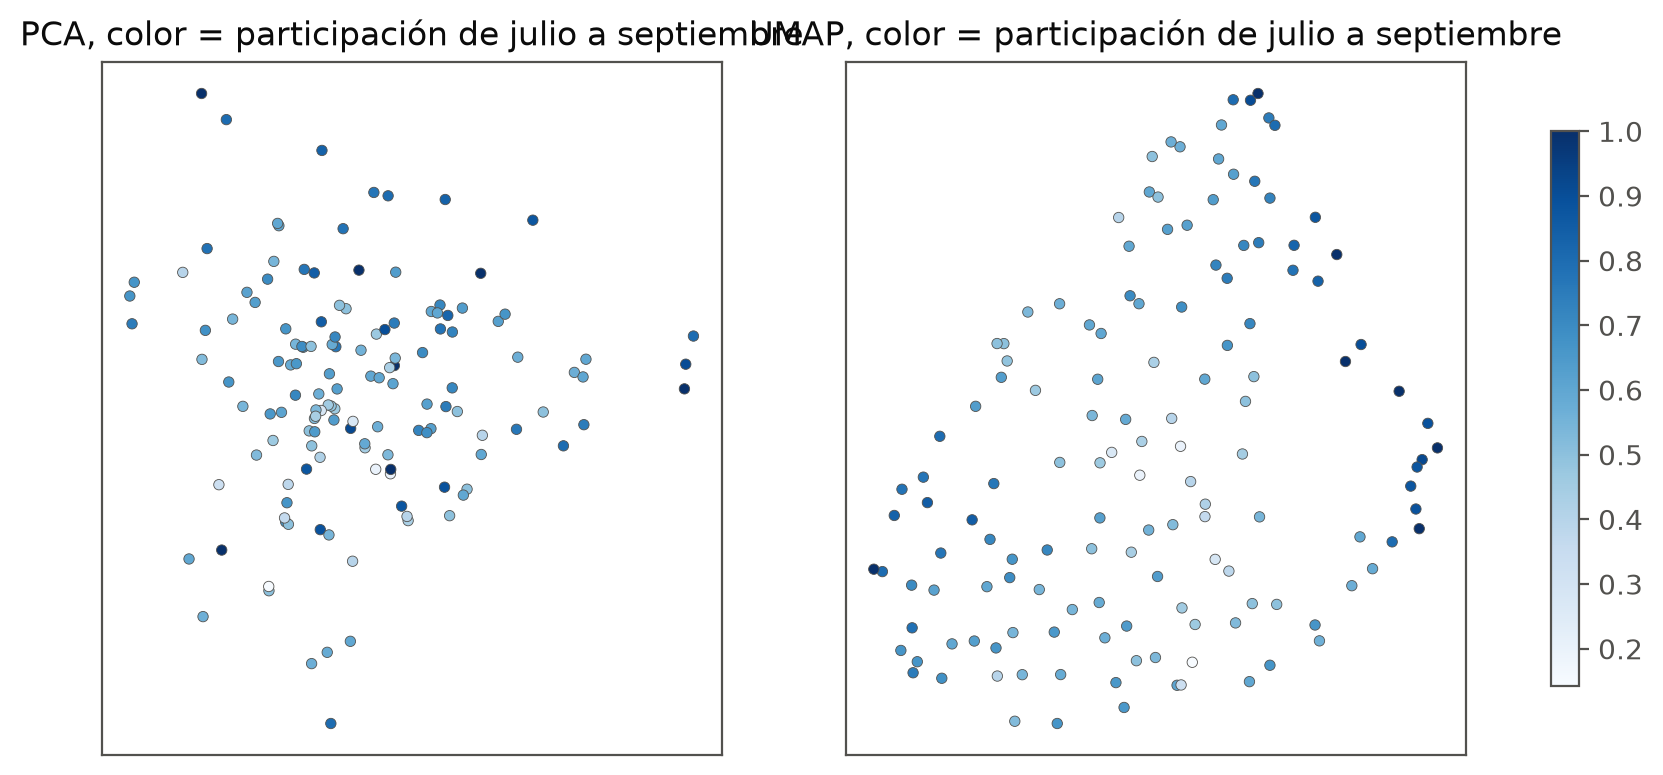

In [ ]:
embeddings = embed_2d(profiles.to_numpy(), perplexity=20)
_fig, _axes = plt.subplots(1, 2, figsize=(11, 4.5))
_color = profiles[[7, 8, 9]].sum(axis=1)
for _ax, _method in zip(_axes, ["PCA", "UMAP"]):
    _points = embeddings[_method]
    _scatter = _ax.scatter(
        _points[:, 0],
        _points[:, 1],
        c=_color,
        cmap="Blues",
        s=14,
        edgecolors="#52514e",
        linewidths=0.3,
    )
    _ax.set_title(f"{_method}, color = participación de julio a septiembre")
    _ax.set_xticks([])
    _ax.set_yticks([])
_fig.colorbar(_scatter, ax=_axes, shrink=0.8)
_fig

In [ ]:
embedding_quality(profiles.to_numpy(), embeddings)

,trustworthiness
PCA,0.826
t-SNE,0.878
UMAP,0.857


Lectura:

- PC1 explica 33% de la varianza, pero no separa colonias lluviosas de colonias planas: sus
  cargas son julio (−0.48) contra agosto (+0.85). Separa colonias según en qué mes del
  monzón cayeron sus llamadas; PC2 hace lo mismo con julio contra septiembre.
- PC1 apenas se relaciona con la participación de julio a septiembre (Spearman 0.15) y con
  la distancia al cauce (−0.17). Las proyecciones muestran una nube continua, sin grupos.
- Confirma E4: la temporada pega en toda la ciudad, y cuál colonia llama depende de dónde
  cayó cada tormenta, no de un rasgo fijo visible en la red hidrográfica 1:50k.
- Confiabilidad de las proyecciones: PCA 0.83, t-SNE 0.88, UMAP 0.86.

## E7. ¿El texto confirma la causa?

Porcentaje de textos de cada mes que mencionan la lluvia, en las descripciones de baches y
en las publicaciones de Agua de Hermosillo (texto y OCR).

In [ ]:
_pattern = r"\bllov|\blluvi|\btormenta|\bchubasc|\baguacer|\bencharc|\binund"
_posts_text = posts["text"].fillna("") + " " + posts["ocr_text"].fillna("")
text_by_month = pd.DataFrame(
    {
        "baches": baches["description"]
        .fillna("")
        .str.lower()
        .str.contains(_pattern)
        .groupby(baches["date"].dt.month)
        .mean()
        .mul(100),
        "aguah": _posts_text.str.lower()
        .str.contains(_pattern)
        .groupby(posts["date"].dt.month)
        .mean()
        .mul(100),
    }
).round(1)
text_by_month.index.name = "mes"
text_by_month

,baches,aguah
mes,,
1,0.6,1.6
2,0.7,0.2
3,1.1,0.0
4,0.7,0.8
5,0.5,0.0
6,0.7,1.0
7,0.7,7.0
8,1.5,7.5
9,1.2,1.9


Lectura:

- En baches la lluvia casi no aparece: entre 0.5% y 1.5% de las descripciones, sin un pico
  claro en temporada. Quien reporta un bache no lo atribuye a la lluvia.
- En Agua de Hermosillo la mención sube de menos de 2% a 7% en julio y agosto. Leídas a
  mano, esas publicaciones atribuyen a las tormentas apagones que detienen el bombeo,
  salidas de operación en El Novillo y pipas de apoyo "tras las afectaciones ocasionadas
  por las lluvias".
- Es decir, la lluvia sí afecta el suministro, pero como episodios que el conteo diario de
  emergencias no separa del resto. El texto de Agua de Hermosillo sirve como evidencia
  cualitativa y para etiquetar eventos en el tablero.

## Decisión

| Exploración | Resultado | Decisión |
|---|---|---|
| E8 cobertura | Ventana común de enero 2022 a septiembre 2025; 67% de llamadas con colonia | Limitaciones del reporte |
| E1 calendario | 911 se concentra en julio a septiembre cada año; baches y AguaH no | Se conserva para 911 |
| E2 lluvia | 911 inundación 21.7 veces, terreno 3.7, drenaje 2.5; baches y AguaH sin respuesta | Hallazgo principal |
| E3 temporada seca | Solo 2023; pipas concentradas en julio y agosto de 2024 | Se descarta como temporada; AguaH queda como contexto |
| E4 colonias | Diferencia de mediana por cauce, sin relación por colonia ni persistencia | Descriptivo, sin diagnóstico espacial |
| E5 anomalías | 83% en julio a septiembre, 92% con lluvia previa, solo 36% con 10 mm o más | Se conserva; expone el límite del reanálisis |
| E6 perfiles | PC1 separa julio de agosto, no colonias lluviosas; sin relación con el cauce | Se conserva como apoyo de E4 |
| E7 texto | Baches no nombran la lluvia; AguaH la nombra como causa de fallas de bombeo | Evidencia cualitativa y etiquetas de eventos |

Pregunta redefinida: ¿cuánto aumentan las emergencias urbanas reportadas al 911 en
Hermosillo cuando llueve, qué tipos de incidente responden y en qué colonias se
concentran en cada temporada de lluvias?